In [16]:
import sys
import os
import glob
import importlib

import tqdm

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

In [18]:
import jax
jax.config.update('jax_enable_x64', True)

import jax.random
import jax.numpy as jnp

In [19]:
import discovery as ds
import discovery.models.nanograv as ds_nanograv
import discovery.samplers.numpyro as ds_numpyro
importlib.reload(ds)
importlib.reload(ds_nanograv)
importlib.reload(ds_numpyro)
importlib.reload(ds.pulsar)
importlib.reload(ds.likelihood)
importlib.reload(ds.signals)
importlib.reload(ds.matrix)
importlib.reload(ds.prior)

<module 'discovery.prior' from '/h/mit227/discovery-ppa/src/discovery/prior.py'>

In [ ]:
psr = ds.Pulsar.read_feather('/DATA/CARINA_4/mit227/subband_PA_data/J0738-4042.PA.head_derot.minusSBmean.feather', json_metadata=False)
psr.pdist = 1.6 # kpc
print(psr)

<Pulsar J0738-4042: 864 res, 0 pars>


In [21]:
with np.printoptions(threshold=sys.maxsize):
    print(np.degrees(psr.residuals))
    print(np.degrees(psr.toaerrs))

[ 1.08997842e+01  5.75117932e+00  3.93074660e+00  3.63048731e+00
  1.02471188e+01  4.33048384e+00  3.25664564e+00  3.11333396e+00
  2.42313168e+00  2.67526033e+00  3.18415664e+00  9.13495975e+00
  5.83109287e+00  5.71247125e+00  5.02145635e+00  4.52407944e+00
  3.90338512e+00  5.70686523e+00  4.20023257e+00  9.40232208e+00
  8.74724531e+00  3.94925115e+00  3.61186514e+00  3.45987041e+00
  3.34897411e+00  2.48688620e+00  8.66173660e+00  8.07442563e+00
  3.90286647e+00  3.05464818e+00  2.60927676e+00  1.80158652e+00
  2.96539713e+00  4.16074033e+00  9.12027476e+00  3.62093467e+00
  2.55570562e+00  2.24725583e+00  2.10711248e+00  1.63758924e+00
 -1.38903296e+00  2.56531213e+00  1.55571489e+01  7.17713903e+00
  5.36256803e+00  4.97231757e+00  4.22319718e+00  4.35381038e+00
  5.08513992e+00  1.21287353e+01  1.12909763e+01  6.83368996e+00
  5.53125676e+00  3.61791967e+00  4.16475924e+00  3.76889972e+00
  5.39196370e+00  1.19832230e+01  9.46939398e+00  6.33605619e+00
  4.72037481e+00  4.07207

In [22]:
with np.printoptions(threshold=sys.maxsize):
    print(psr.freqs)
    print(psr.subbands)

[ 819.175 1059.384 2764.755 3259.407 3807.568 1058.068 1415.945 1780.158
 2106.756 2764.822 3258.297 3808.045  833.269 1058.153 1416.926 1780.96
 2104.557 2764.772 3258.068 3807.283  813.632 1056.051 1412.767 1779.423
 2106.266 2764.85  3804.828  807.544 1058.206 1415.966 1780.918 2106.049
 2764.817 3258.315 3807.252 1063.53  1415.511 1780.823 2106.756 2765.24
 3258.542 3809.293  816.1   1064.456 1409.231 1778.828 2107.04  2764.758
 3258.549 3806.348  817.5   1066.155 1420.007 1778.215 2107.275 2764.831
 3258.299 3804.746  817.22  1056.201 1417.805 1779.956 2106.59  2764.758
 3258.551 3807.398  802.055 1085.047 1419.324 1780.121 2107.275 2764.755
 3258.742 3807.048  805.39  1061.539 1411.352 1778.742 2107.153 2769.102
 3258.315 3804.675  810.523 1416.491 1779.394 2107.275 2764.776 3258.547
 3805.294  811.141 1067.46  1416.214 1779.36  2107.275 2764.755 3258.434
 3808.326  827.085 1064.251 1413.633 1780.095 2107.275 2764.755 3258.778
 3808.746  829.205 1064.724 1413.465 1780.09  2107.27

In [23]:
obs_PA_dict = {}
for obs in psr.obsnames:
    mask = psr.obsnames == obs
    obs_sbs = psr.subbands[mask]
    obs_PAs = psr.residuals[mask]

    PA_list_for_dict = []
    i_in_orig = 0
    for sb in range(1,8+1):
        if sb in obs_sbs:
            PA_list_for_dict.append(obs_PAs[i_in_orig])
            i_in_orig += 1
        else:
            PA_list_for_dict.append(np.nan)

    obs_PA_dict[obs] = PA_list_for_dict

pd.set_option('display.max_rows', None)
df = pd.DataFrame(obs_PA_dict, index=range(1,8+1)).T
df

,1,2,3,4,5,6,7,8
uwl_181217_113047_b4,0.190237,0.100377,NaN,NaN,NaN,0.068604,0.063364,0.178846
uwl_190116_093346_b4,NaN,0.075581,0.056839,0.054338,0.042292,0.046692,0.055574,0.159435
uwl_190217_065425_b4,0.101772,0.099701,0.087641,0.078960,0.068127,0.099604,0.073308,0.164101
uwl_190314_072559_b4,0.152668,0.068927,0.063039,0.060386,0.058451,0.043404,NaN,0.151176
uwl_190315_053115_b4,0.140925,0.068118,0.053314,0.045540,0.031444,0.051756,0.072619,0.159179
uwl_190505_014929_b4,NaN,0.063197,0.044605,0.039222,0.036776,0.028581,-0.024243,0.044773
uwl_190611_234007_b4,0.271523,0.125265,0.093594,0.086783,0.073709,0.075988,0.088752,0.211686
uwl_190705_002313_b4,0.197065,0.119270,0.096539,0.063145,0.072689,0.065780,0.094108,0.209147
uwl_190705_221017_b4,0.165272,0.110585,0.082386,0.071071,0.064453,0.029214,0.045632,0.124529
uwl_190727_203534_b4,0.208918,0.125951,0.096976,0.082583,0.088554,0.072239,0.085822,0.163078


In [24]:

pd.reset_option('display.max_rows')
        

[]

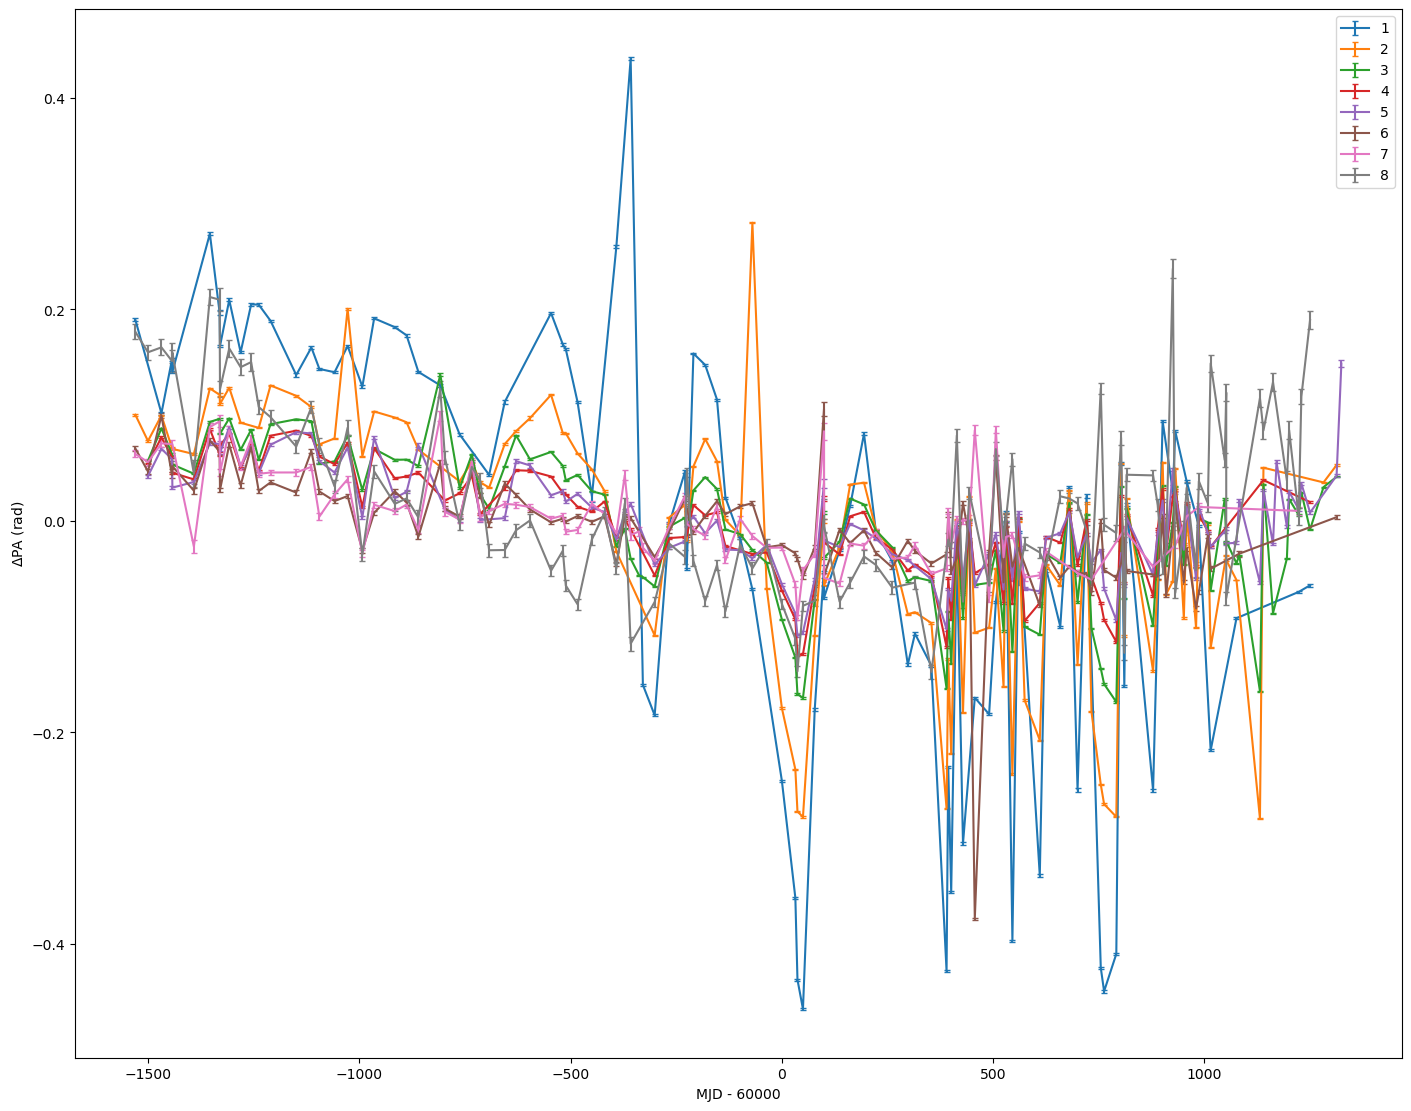

In [25]:
from astropy.time import Time

fig, ax = plt.subplots(1, 1, figsize=(14, 11), layout='constrained')

for sb in range(1,8+1):
    mask = psr.subbands == sb
    t = Time(psr.toas[mask], format='unix', scale='utc')
    ax.errorbar(t.mjd-60000, 
                # np.degrees(
                    psr.residuals[mask],
                    # ), 
                # np.degrees(
                    psr.toaerrs[mask],
                    # ), 
                capsize=2.5, label=sb)

ax.set_xlabel('MJD - 60000')
ax.set_ylabel('$\\Delta$PA (rad)')
ax.legend()
plt.plot()

In [51]:
%timeit ds.makegp_ecorr_simple(psr)

4.57 ms ± 1.68 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [50]:
%timeit ds.makegp_ecorr(psr)

6.28 ms ± 1.39 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [49]:
%timeit ds.makegp_erm(psr)

7.85 ms ± 1.7 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


#### Measurement noise only, no backends

In [11]:
m = ds.PulsarLikelihood([psr.residuals,#np.nan_to_num(psr.residuals, nan=0.0),
                         ds.makenoise_measurement_simple(psr)])

In [12]:
m.logL.params

['J0738-4042_efac', 'J0738-4042_log10_t2equad']

In [13]:
p0 = ds.sample_uniform(m.logL.params)
print(p0)
print(m.logL(p0))

{'J0738-4042_efac': 4.082628475864903, 'J0738-4042_log10_t2equad': -2.5719463664293096}
-22037.11958872664


#### Add ECORR noise (GP), free params, no backends

In [14]:
m_ecorr = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr)])
print(m_ecorr.logL.params)

['J0738-4042_efac', 'J0738-4042_log10_ecorr', 'J0738-4042_log10_t2equad']


In [15]:
p0 = ds.sample_uniform(m_ecorr.logL.params)
print(p0)
print(f'w/  ECORR: {m_ecorr.logL(p0)}')
print(f'w/o ECORR: {m.logL(p0)}')

{'J0738-4042_efac': 2.620922002334931, 'J0738-4042_log10_ecorr': -2.34529122663705, 'J0738-4042_log10_t2equad': -2.8978810317456225}
w/  ECORR: -74575.75442527013
w/o ECORR: -188149.86914626937


#### Add RM noise

In [16]:
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
print(m_RM.logL.params)

['J0738-4042_efac', 'J0738-4042_log10_ecorr', 'J0738-4042_log10_t2equad', 'J0738-4042_rmgp_gamma', 'J0738-4042_rmgp_log10_A']


In [17]:
p0 = ds.sample_uniform(m_RM.logL.params)
print(p0)
print(f'Noise:          {m.logL(p0):e}')
print(f'Noise+ECORR:    {m_ecorr.logL(p0):e}')
print(f'Noise+ECORR+RM: {m_RM.logL(p0):e}')

{'J0738-4042_efac': 5.995384112897244, 'J0738-4042_log10_ecorr': -1.7652005540978961, 'J0738-4042_log10_t2equad': -1.6173428662734848, 'J0738-4042_rmgp_gamma': 1.7583576415877156, 'J0738-4042_rmgp_log10_A': -7.170068684695438}
Noise:          1.564578e+03
Noise+ECORR:    1.568783e+03
Noise+ECORR+RM: 1.555954e+03


[]

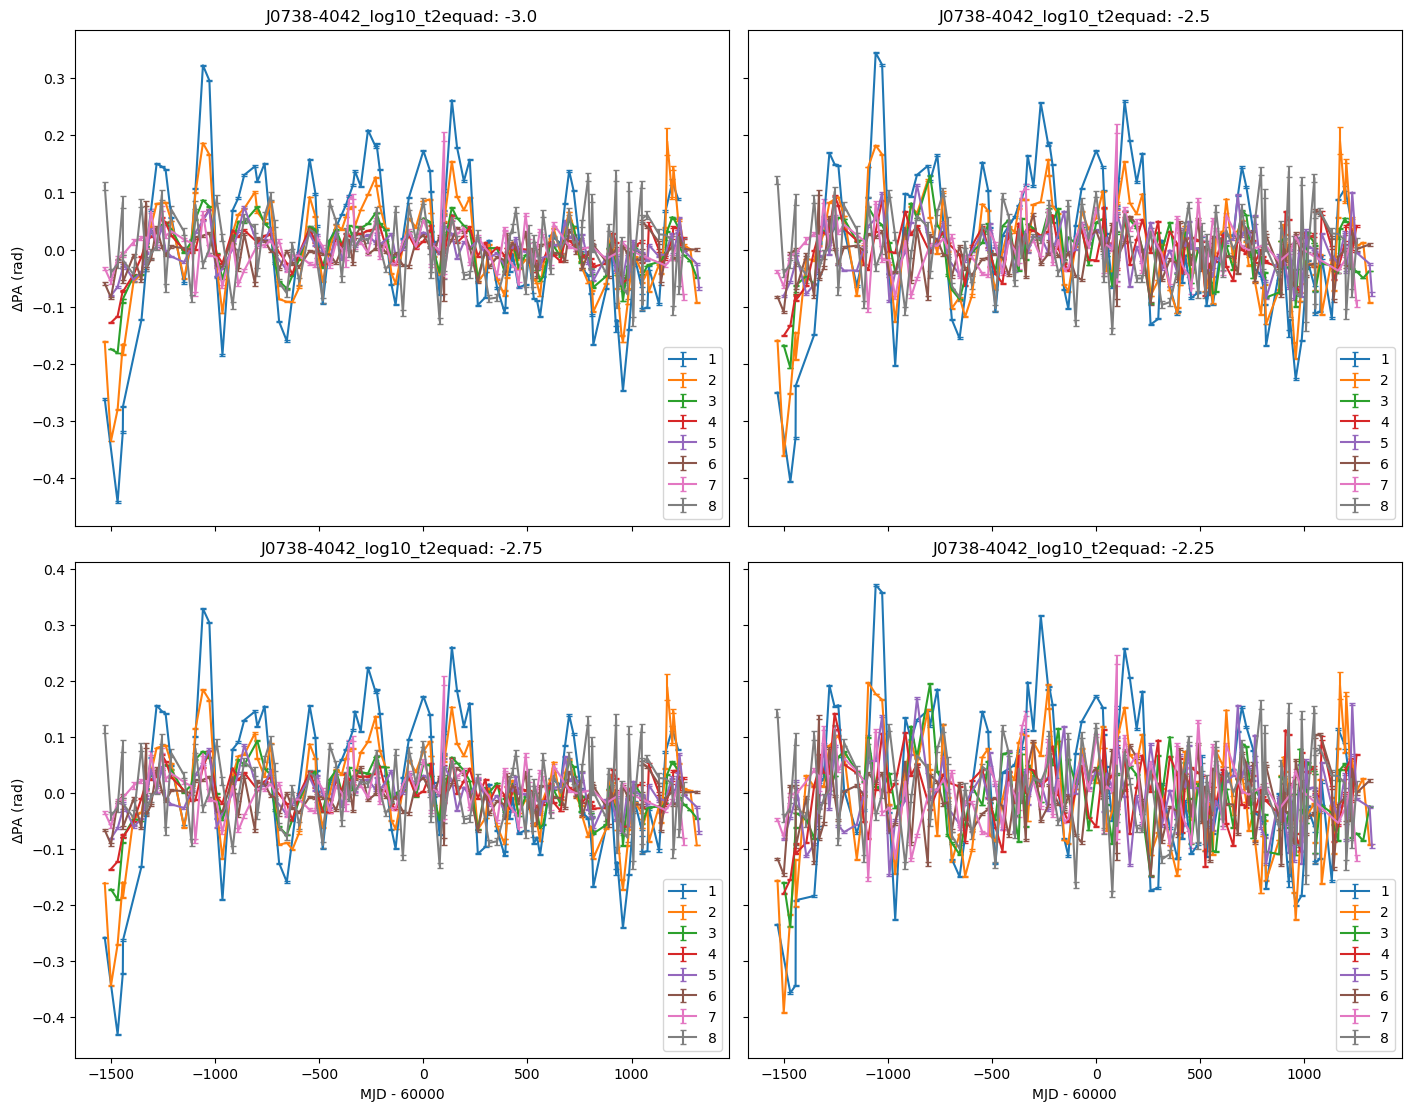

In [18]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # fix parameters to reasonable value
        params = {
            'J0738-4042_efac':10.000,
            'J0738-4042_log10_ecorr':-5.000,
            'J0738-4042_log10_t2equad':-3.000+(i+2*j)/4,
            'J0738-4042_rmgp_gamma':0.986,
            'J0738-4042_rmgp_log10_A':-8.121
            }

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42)#+i+2*j)
        key, res = m_RM.sample(key, params)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.set_title(f'J0738-4042_log10_t2equad: {params['J0738-4042_log10_t2equad']}')
        ax.legend()

plt.plot()

#### Add achromatic red noise

In [ ]:
m_red = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp'),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, name='rednoise')
                         ])
print(m_red.logL.params)

['J0738-4042_efac', 'J0738-4042_log10_ecorr', 'J0738-4042_log10_t2equad', 'J0738-4042_rednoise_gamma', 'J0738-4042_rednoise_log10_A', 'J0738-4042_rmgp_gamma', 'J0738-4042_rmgp_log10_A']


[]

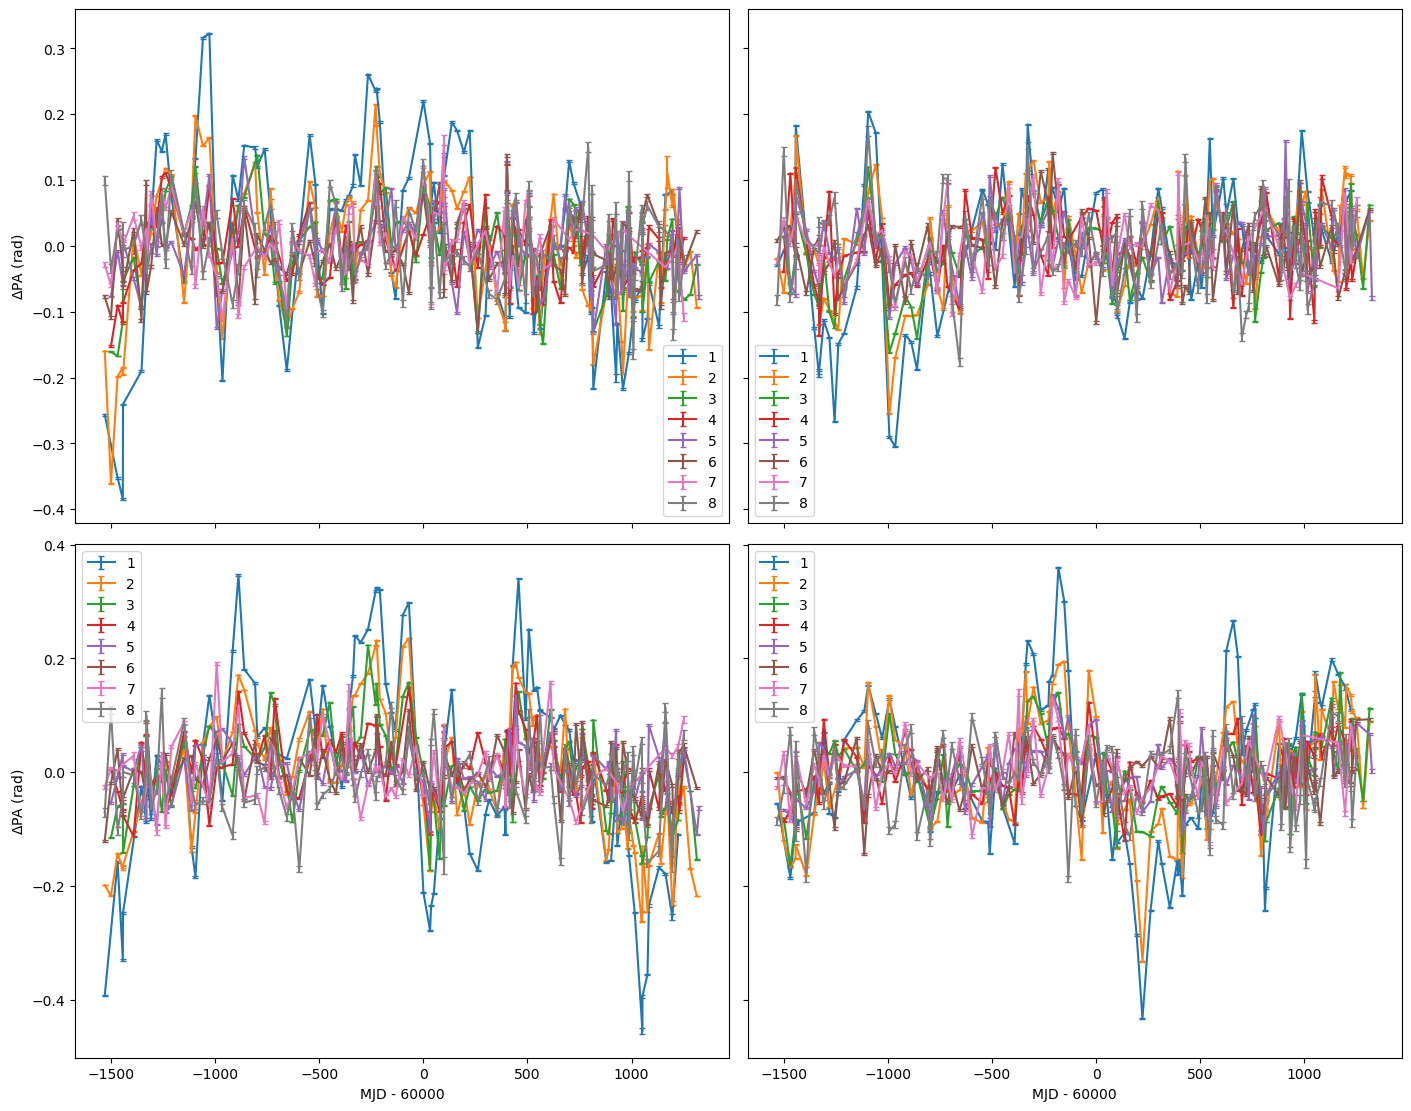

In [22]:
sampler = m_red.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # fix parameters to reasonable value
        # params = {
        #     'J0835-4510_efac':4.0,#7.405,
        #     'J0835-4510_log10_ecorr':-2.006,
        #     'J0835-4510_log10_t2equad':-2.287,
        #     'J0835-4510_rednoise_gamma':2.0, 
        #     'J0835-4510_rednoise_log10_A':-9,
        #     'J0835-4510_rmgp_gamma':1.118,
        #     'J0835-4510_rmgp_log10_A':-8.140
        #     }
        params = {
        'J0738-4042_efac':6.635,
        'J0738-4042_log10_ecorr':-1.603,
        'J0738-4042_log10_t2equad':-2.252,
        'J0738-4042_rednoise_gamma':1.403,
        'J0738-4042_rednoise_log10_A':-9.615,
        'J0738-4042_rmgp_gamma':1.192,
        'J0738-4042_rmgp_log10_A':-8.135
        }

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = sampler(key, params)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

In [20]:
from discovery import prior
from discovery.params import Params, make_layout

import numpyro
from numpyro import infer, distributions as dist

In [ ]:
logL = m_RM.logL

# static layout shared by every Params built inside the model
layout, size = make_layout(logL.params)

# flat uniform bounds, one entry per (scalar) parameter
bounds = [prior.getprior_uniform(p) for p in logL.params]
print(bounds)
lo = jnp.array([b[0] for b in bounds])
hi = jnp.array([b[1] for b in bounds])

def numpyro_model():
    raw = numpyro.sample('raw', dist.Uniform(lo, hi))   # one (P,) array site
    numpyro.factor('logl', logL(Params(raw, layout)))

[[0.1, 10], [-3, -1], [-3.5, -1.5], [0, 7], [-10, -8], [0, 2], [-9, -7]]


In [23]:
sampler = infer.MCMC(infer.NUTS(numpyro_model),
                     num_warmup=100, num_samples=100)
sampler.run(jax.random.PRNGKey(42))

warmup:  20%|█▉        | 39/200 [12:41<52:23, 19.53s/it, 255 steps of size 3.06e-02. acc. prob=0.74]  


KeyboardInterrupt: 

In [30]:
raw_samples = sampler.get_samples()['raw']
# print(raw_samples)

p_fit = {}
for i, name in enumerate(logL.params):
    col = raw_samples[:, i]
    print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  bounds={bounds[i]}')
    p_fit[name] = col.mean()

print(p_fit)
print(f'{logL(p_fit):e}')

J0738-4042_efac                mean=+9.872  std=0.104  bounds=[0.1, 10]
J0738-4042_log10_ecorr         mean=-1.480  std=0.036  bounds=[-3, -1]
J0738-4042_log10_t2equad       mean=-2.387  std=0.015  bounds=[-3.5, -1.5]
J0738-4042_rednoise_gamma      mean=+3.267  std=0.592  bounds=[0, 4]
J0738-4042_rednoise_log10_A    mean=-9.174  std=0.258  bounds=[-10, -8]
J0738-4042_rmgp_gamma          mean=+1.151  std=0.253  bounds=[0, 2]
J0738-4042_rmgp_log10_A        mean=-8.098  std=0.048  bounds=[-9, -7]
{'J0738-4042_efac': Array(9.8719141, dtype=float64), 'J0738-4042_log10_ecorr': Array(-1.480073, dtype=float64), 'J0738-4042_log10_t2equad': Array(-2.38749469, dtype=float64), 'J0738-4042_rednoise_gamma': Array(3.2668505, dtype=float64), 'J0738-4042_rednoise_log10_A': Array(-9.17446606, dtype=float64), 'J0738-4042_rmgp_gamma': Array(1.15145368, dtype=float64), 'J0738-4042_rmgp_log10_A': Array(-8.09795545, dtype=float64)}
2.154003e+03


<class 'jaxlib._jax.ArrayImpl'>


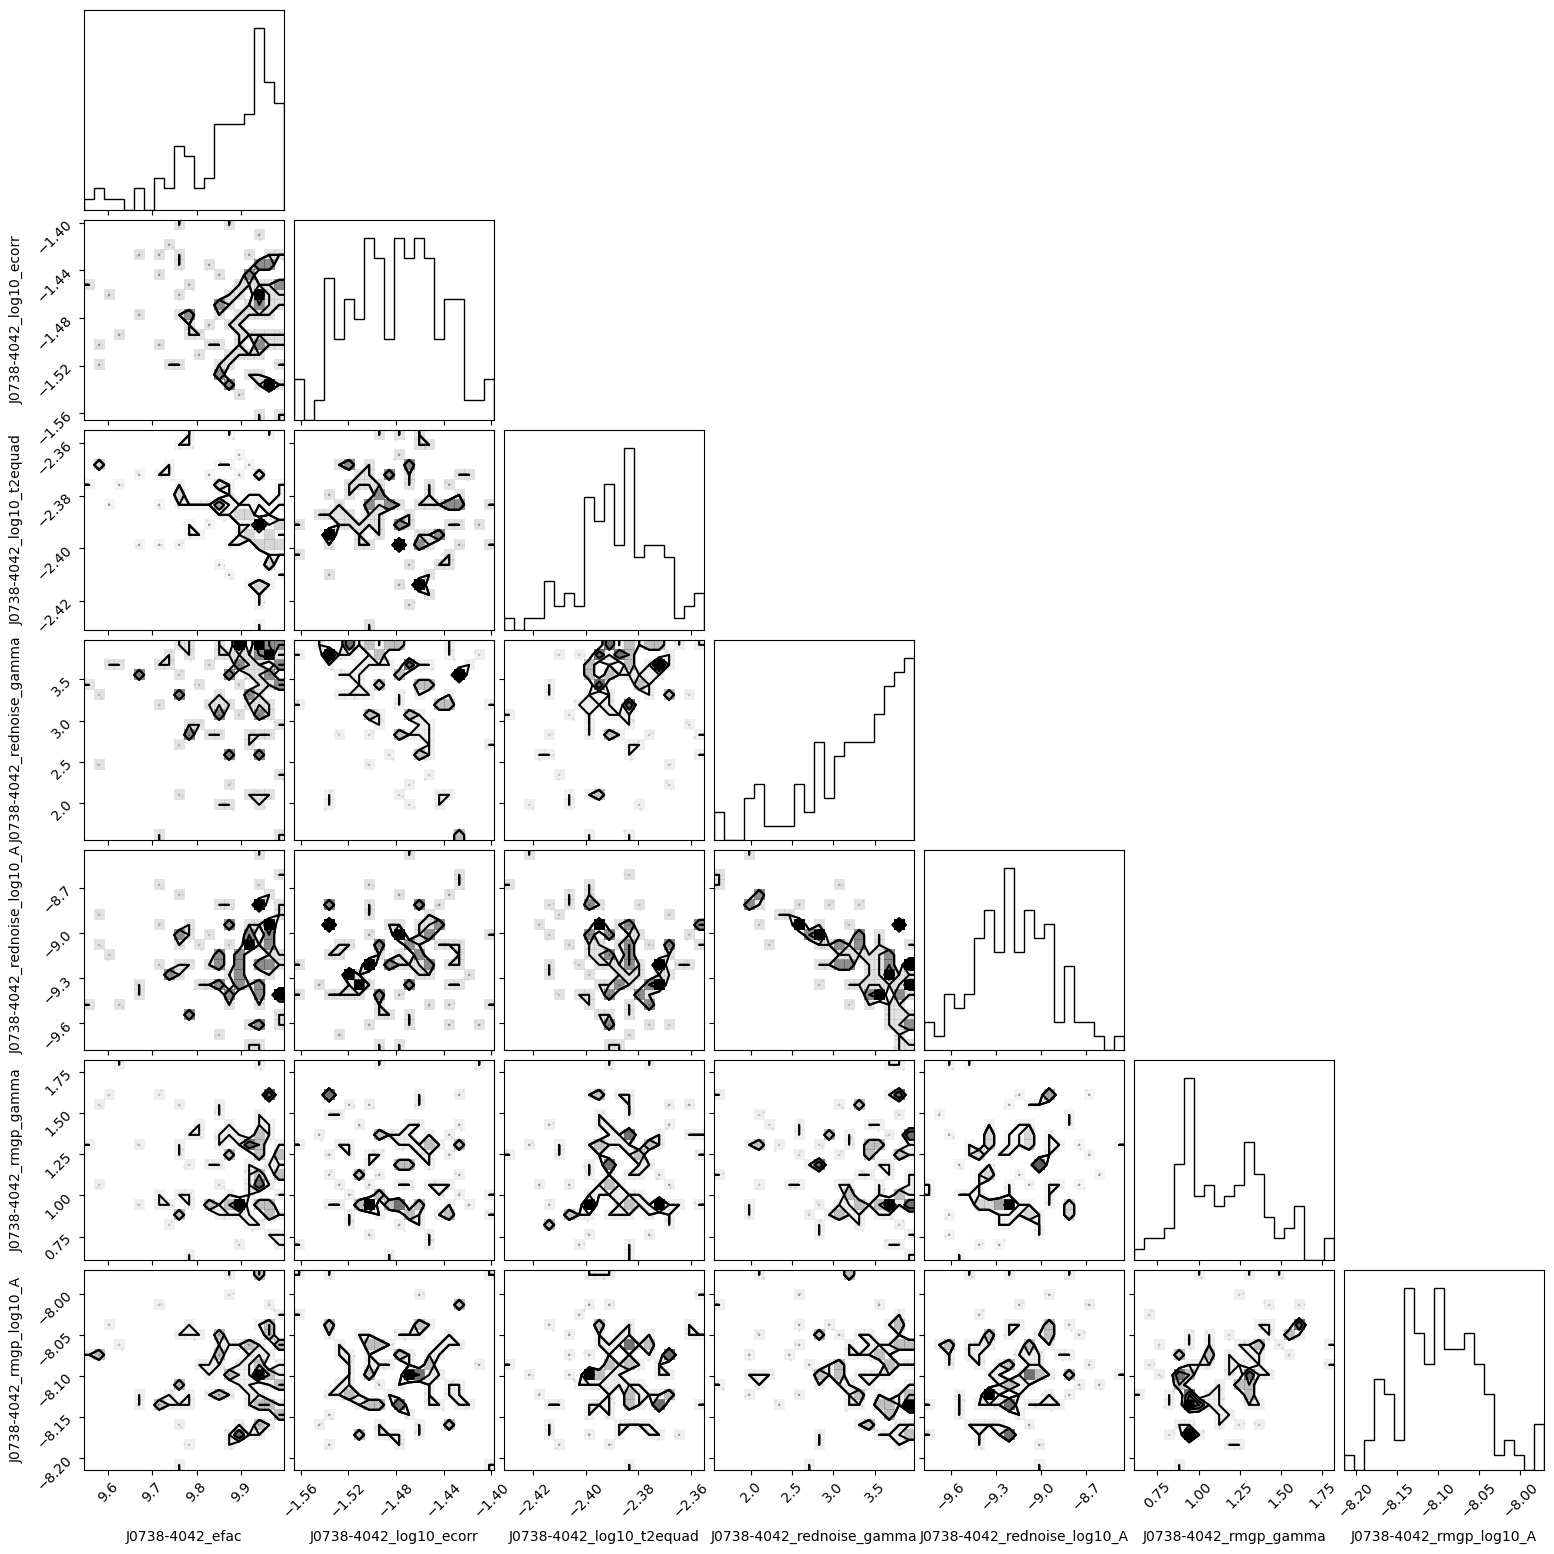

In [31]:
import corner 
figure = corner.corner(
    np.array(raw_samples),
    labels=logL.params
    )
print(type(raw_samples))

[]

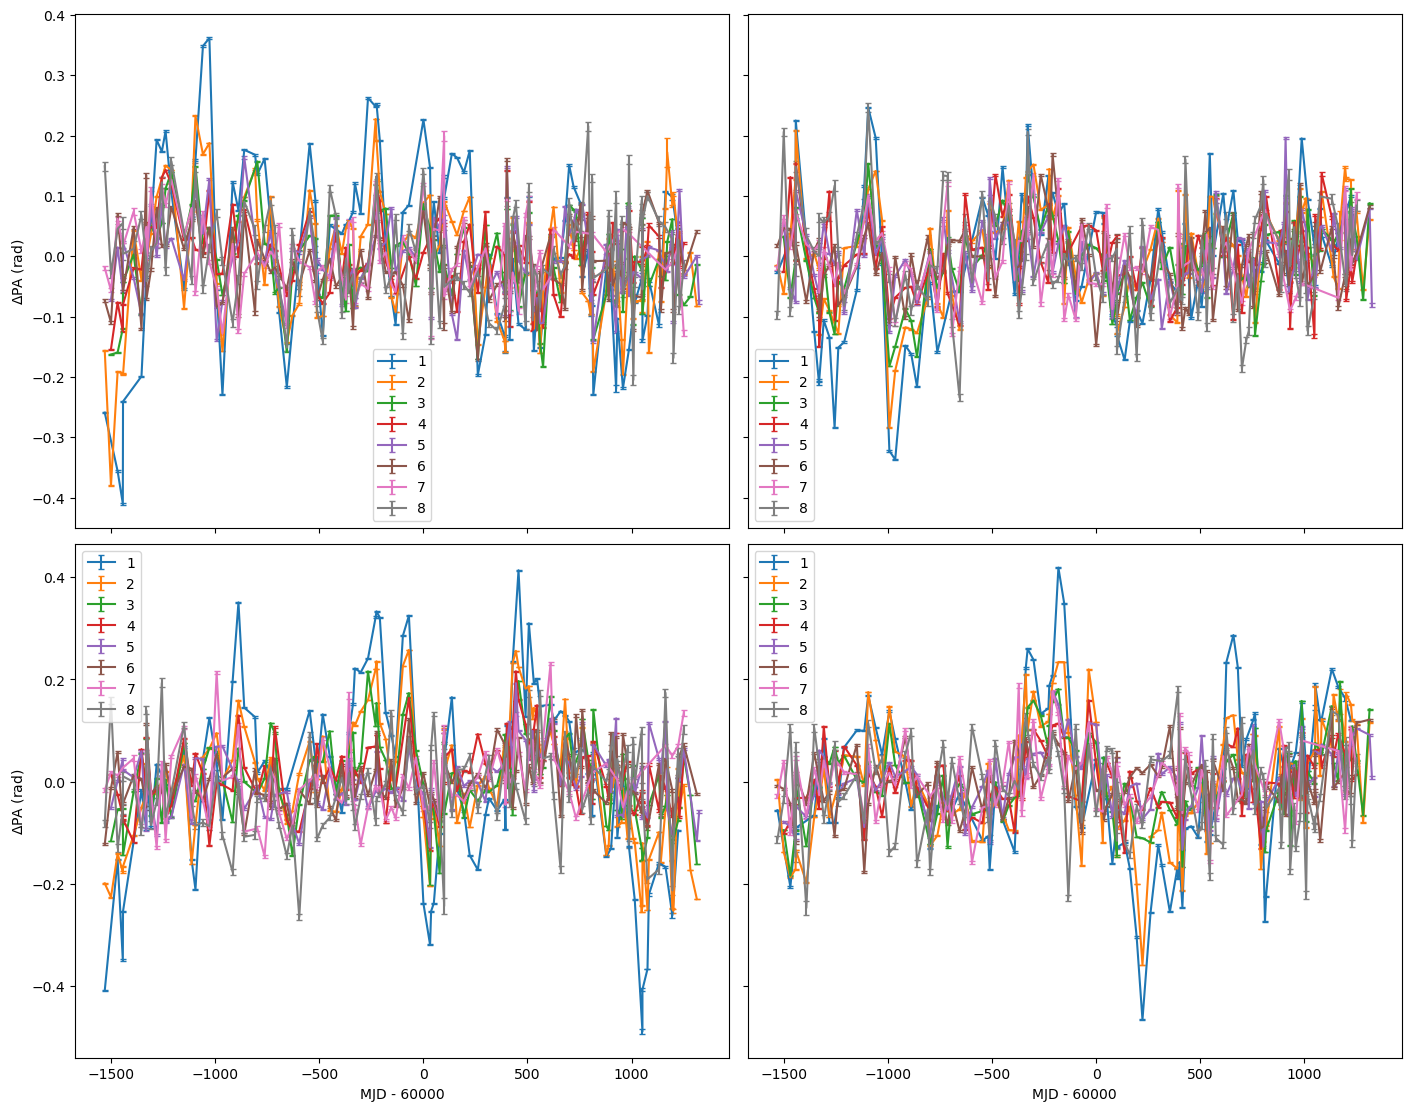

In [32]:
# sampler = m_red.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_red.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()